In [74]:
import numpy as np
from scipy.integrate import odeint
from scipy.optimize import fsolve
import matplotlib.pyplot as plt

In [75]:
def plot_dynamics(Y, K, t, neg, num):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (10, 4))

    fig.tight_layout()

    ax1.plot(t, Y, label = "Y")
    ax1.plot(t, K, label = "K")

    ax1.set_title("Dynamics")
    ax1.set_xlabel("t")

    ax1.legend()

    ax2.plot(Y, K)

    ax2.set_title("Phase portrait")
    ax2.set_xlabel("Y")
    ax2.set_ylabel("K")

    if (neg == True):
        plt.savefig("../Figures/Sigmoid/Neg_dynamics.png")

    if (neg == False):
        plt.savefig(f"../Figures/Sigmoid/Pos_dynamics_{num}.png")

In [76]:
# Investment function: I(Y) = A / 1 + e^[-B(Y-Y0)]

def I(Y, A, B, Y0):
    I = A / (1 + np.exp(-B*(Y-Y0)))
    return I

In [77]:
# Derivative of the investment function

def I_der(Y, A, B, Y0):
    I_der = A * B * np.exp(-B * (Y - Y0)) / (1 + np.exp(-B * (Y - Y0)))**2
    return I_der

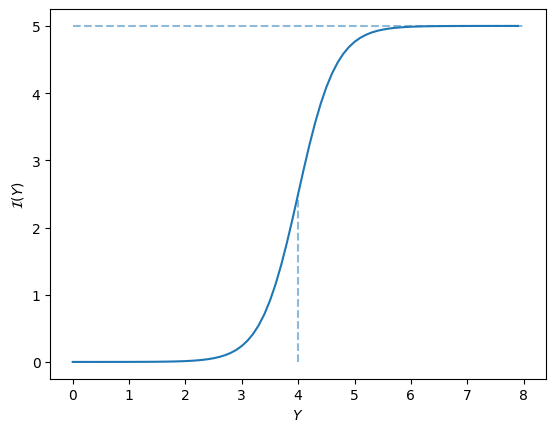

In [78]:
# Plot of the investment function

A = 5
B = 3
Y0 = 4

Y = np.arange(0, 8, 0.1)

I_Y = I(Y, A, B, Y0)

fig, ax = plt.subplots(1, 1)

ax.plot(Y, I_Y)

ax.hlines(A, 0, 8, ls = "--", alpha = 0.5)

ax.vlines(Y0, 0, 2.5, ls = "--", alpha = 0.5)

ax.set_xlabel(r"$Y$")
ax.set_ylabel(r"$\mathcal{I}(Y)$")

plt.savefig("../Figures/Sigmoid/Investment_function.png")

In [79]:
# Vector field

def vector_field(x, t, alpha, beta, gamma, delta, A, B, Y0):
    Y = x[0]
    K = x[1]

    f_Y = alpha * (I(Y, A, B, Y0) - beta*K - gamma*Y)
    f_K = I(Y, A, B, Y0) - beta*K - delta*K

    f = np.array((f_Y, f_K))

    return f

In [80]:
# Parameters of the model

beta = 0.8
gamma = 0.5
delta = 0.5

A = 3.2
B = 1.5
Y0 = 1.2

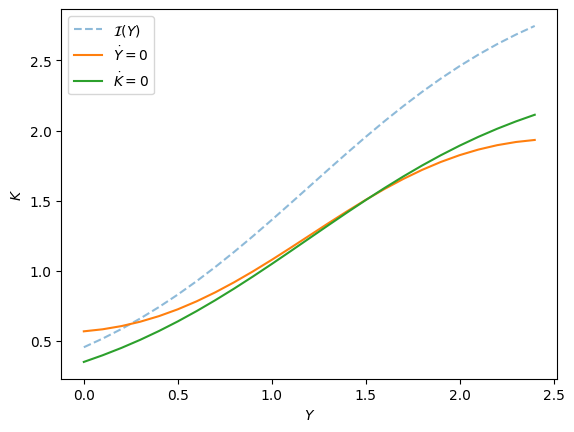

In [81]:
# Null-clines

Y = np.arange(0, 2.5, 0.1)

I_Y = I(Y, A, B, Y0)

K1 = (I(Y, A, B, Y0) - gamma * Y) / beta
K2 = I(Y, A, B, Y0) / (beta + delta)

fig, ax = plt.subplots(1, 1)

ax.plot(Y, I_Y, ls = "--", alpha = 0.5, label = r"$\mathcal{I}(Y)$")
ax.plot(Y, K1, label = r"$\dot{Y} = 0$")
ax.plot(Y, K2, label = r"$\dot{K} = 0$")

ax.set_xlabel(r"$Y$")
ax.set_ylabel(r"$K$")

ax.legend()

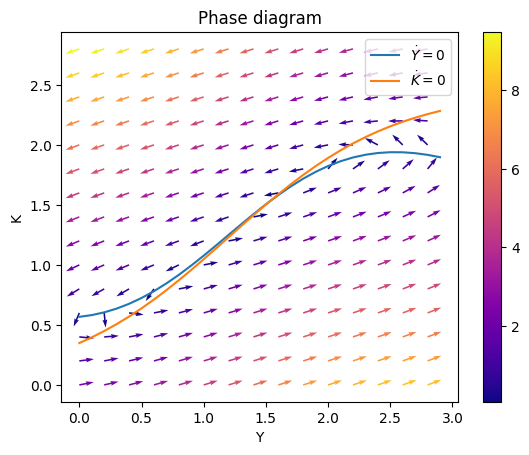

In [82]:
# Vector field and null-clines

alpha = 5

fig, ax = plt.subplots(1, 1)

Y = np.arange(0, 3, 0.1)
K1 = (I(Y, A, B, Y0) - gamma * Y) / beta
K2 = I(Y, A, B, Y0) / (beta + delta)

ax.plot(Y, K1, label = r"$\dot{Y} = 0$")
ax.plot(Y, K2, label = r"$\dot{K} = 0$")

Y, K =  np.meshgrid(np.arange(0, 3, 0.2), np.arange(0, 3, 0.2))

x = np.array((Y, K))

t = 0
f = vector_field(x, t, alpha, beta, gamma, delta, A, B, Y0)

f_Y = f[0]
f_K = f[1]

f_norm = np.sqrt(f_Y**2 + f_K**2)

field = ax.quiver(Y, K, f_Y/f_norm, f_K/f_norm, f_norm, cmap = "plasma", angles = "xy")
plt.colorbar(field, ax = ax)

ax.set_title("Phase diagram")
ax.set_xlabel("Y")
ax.set_ylabel("K")

ax.legend()

plt.savefig("../Figures/Sigmoid/Vector_field.png")

Y_eq = 1.524735465239864, K_eq = 1.524735465239864


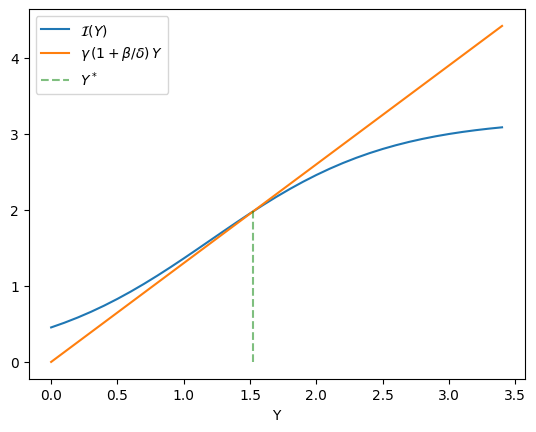

In [83]:
# Equilibrium

def f(Y):
    f = I(Y, A, B, Y0) - gamma * (1 + beta/delta) * Y
    return f

Y_eq = fsolve(f, 1)[0]

fig, ax = plt.subplots(1, 1)

Y = np.arange(0, 3.5, 0.1)
f1 = I(Y, A, B, Y0)
f2 = gamma * (1 + beta/delta) * Y

ax.plot(Y, f1, label = r"$\mathcal{I}(Y)$")
ax.plot(Y, f2, label = r"$\gamma \, (1 + \beta/\delta) \, Y$")

ax.vlines(Y_eq, 0, I(Y_eq, A, B, Y0), ls = "--", color = "green", alpha = 0.5, label = r"$Y^*$")

ax.set_xlabel("Y")
ax.legend()

K_eq = gamma/delta * Y_eq

print(f"Y_eq = {Y_eq}, K_eq = {K_eq}")

plt.savefig("../Figures/Sigmoid/Equilibrium.png")

alpha s.t. trA = 0: 2.0584530731562833


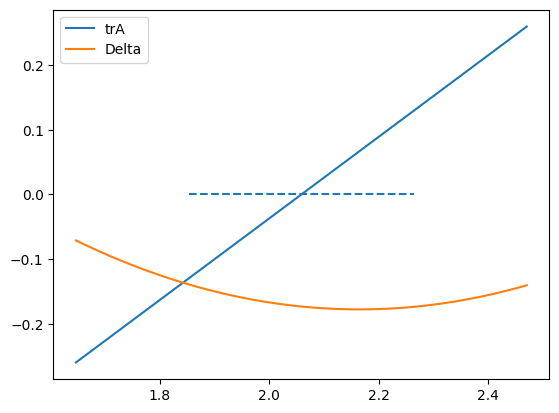

In [84]:
# Around Y_eq, K_eq

def trA(alpha):
    trA = alpha * (I_der(Y_eq, A, B, Y0) - gamma) - (beta + delta)
    return trA

alpha_zero_trA = (beta + delta)/(I_der(Y_eq, A, B, Y0) - gamma)

print(f"alpha s.t. trA = 0: {alpha_zero_trA}")

def detA(alpha):
    detA = -alpha * (delta * I_der(Y_eq, A, B, Y0) - gamma * (beta + delta))
    return detA

def Delta(alpha):
    Delta = (trA(alpha))**2 - detA(alpha)
    return Delta

# plot of trA(alpha) and Delta(alpha) in the range (0.8*alpha_zero_trA, 1.2*alpha_zero_trA)

fig, ax = plt.subplots(1, 1)

alpha = np.linspace(0.8*alpha_zero_trA, 1.2*alpha_zero_trA, 50)

ax.plot(alpha, trA(alpha), label = "trA")
ax.plot(alpha, Delta(alpha), label = "Delta")
ax.hlines(0, 0.9*alpha_zero_trA, 1.1*alpha_zero_trA, ls = "--")

ax.legend()

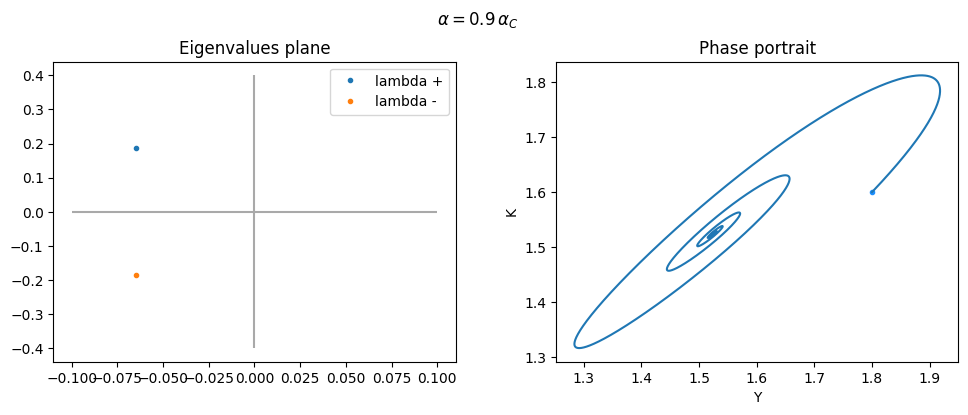

In [85]:
# Negative real part

alpha = 0.9 * alpha_zero_trA

# plot eigenvalues plane and phase portrait
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (10, 4))
fig.subplots_adjust(left = 0.075, right = 0.98, bottom = 0.1, top = 0.85, wspace = 0.25)
fig.suptitle(r"$\alpha = 0.9 \, \alpha_C$ ")

# eigenvalues
lambda_pls = complex(trA(alpha)/2, np.sqrt(-Delta(alpha))/2)
lambda_min = complex(trA(alpha)/2, -np.sqrt(-Delta(alpha))/2)

ax1.plot(lambda_pls.real, lambda_pls.imag, ".", label = "lambda +")
ax1.plot(lambda_min.real, lambda_min.imag, ".", label = "lambda -")

ax1.hlines(0, -0.1, 0.1, color = "darkgrey")
ax1.vlines(0, -0.4, 0.4, color = "darkgrey")

ax1.set_title("Eigenvalues plane")
ax1.legend()


# phase portrait
x0 = np.array((1.8, 1.6))

T = 100
dt = 0.01
t = np.arange(0, T, dt)

x = odeint(vector_field, x0, t, (alpha, beta, gamma, delta, A, B, Y0))

Y = x[:, 0]
K = x[:, 1]

ax2.plot(x0[0], x0[1], ".", color = "dodgerblue")
ax2.plot(Y, K)

ax2.set_title("Phase portrait")
ax2.set_xlabel("Y")
ax2.set_ylabel("K")

plt.savefig("../Figures/Sigmoid/Neg_eigenvalues_phase_portrait.png")

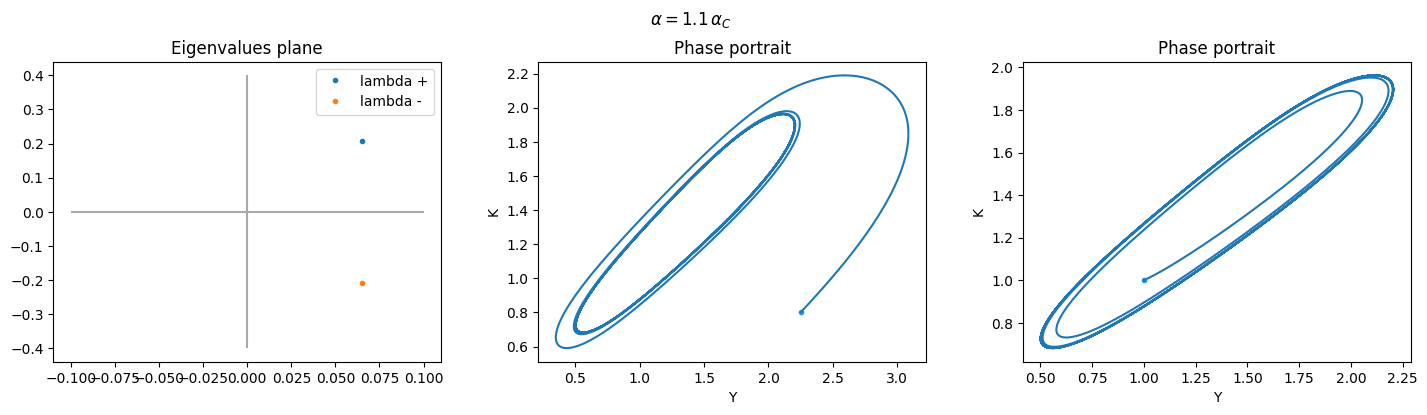

In [86]:
# Positive real part

alpha = 1.1*alpha_zero_trA

# plot eigenvalues plane and phase portrait
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize = (15, 4))
fig.subplots_adjust(left = 0.075, right = 0.98, bottom = 0.1, top = 0.85, wspace = 0.25)
fig.suptitle(r"$\alpha = 1.1 \, \alpha_C$ ")

# eigenvalues
lambda_pls = complex(trA(alpha)/2, np.sqrt(-Delta(alpha))/2)
lambda_min = complex(trA(alpha)/2, -np.sqrt(-Delta(alpha))/2)

ax1.plot(lambda_pls.real, lambda_pls.imag, ".", label = "lambda +")
ax1.plot(lambda_min.real, lambda_min.imag, ".", label = "lambda -")

ax1.hlines(0, -0.1, 0.1, color = "darkgrey")
ax1.vlines(0, -0.4, 0.4, color = "darkgrey")

ax1.set_title("Eigenvalues plane")
ax1.legend()


# phase portrait with initial conditions outside the limiting cycle
x0 = np.array((2.25, 0.8))

T = 100
dt = 0.01
t = np.arange(0, T, dt)

x = odeint(vector_field, x0, t, (alpha, beta, gamma, delta, A, B, Y0))

Y = x[:, 0]
K = x[:, 1]

ax2.plot(x0[0], x0[1], ".", color = "dodgerblue")
ax2.plot(Y, K)

ax2.set_title("Phase portrait")
ax2.set_xlabel("Y")
ax2.set_ylabel("K")


# Phase portrait with initial conditions inside the limiting cycle
x0 = np.array((1, 1))

T = 100
dt = 0.01
t = np.arange(0, T, dt)

x = odeint(vector_field, x0, t, (alpha, beta, gamma, delta, A, B, Y0))

Y = x[:, 0]
K = x[:, 1]

ax3.plot(x0[0], x0[1], ".", color = "dodgerblue")
ax3.plot(Y, K)

ax3.set_title("Phase portrait")
ax3.set_xlabel("Y")
ax3.set_ylabel("K")

plt.savefig("../Figures/Sigmoid/Pos_eigenvalues_phase_portrait.png")